# Benchmark: gamma means

A gamma response is positive, right-skewed, and has variance proportional to the square of its mean. This study asks whether the `GammaReg` family (a gamma likelihood with a log link) recovers that mean as well as a gamma GLM, and whether a P-spline in `gamboost` recovers a smooth log-mean that a linear gamma GLM cannot. A P-spline is a cubic B-spline basis with a penalty on the differences of adjacent coefficients, which keeps the fitted curve smooth.

Two tasks, each with three standard normal predictors. Two of them matter. The shape is 4, so the coefficient of variation is 1/2 and `Var(Y) = mu**2 / 4`. `noise` is unused.

* **linear**: `log mu = 0.15 + 0.55 x1 - 0.30 x2`.
* **smooth**: `log mu = 0.05 + sin(1.5 x1) + 0.30 x2`. The mean is not linear in `x1`.

Each fit sees 1,500 training rows and is scored on the same 4,000 test rows (one test sample per task, four training seeds). mboostrs chooses `mstop`, the number of boosting steps, by 5-fold cross-validation. statsmodels fits a gamma GLM with a log link, linear or with a B-spline in `x1` (`df=8`, bounds -6 and 6). scikit-learn's `GammaRegressor(alpha=0)` is the unpenalised linear gamma regressor. A `Gaussian` `glmboost` is the identity-link baseline. R mboost was not run. Results were measured with mboostrs 0.1.3.

The gamma log score is the mean negative log density on the test rows, in nats per row (lower is better). It is reported twice. **At the fit's shape** uses the shape that fit estimated. For `GammaReg` that is `nuisance()`, the maximum-likelihood shape given the fitted mean. For the statsmodels and scikit-learn GLMs it is the reciprocal of the Pearson dispersion, $\hat\phi = \frac{1}{n-p}\sum_i (y_i - \hat\mu_i)^2/\hat\mu_i^2$, which statsmodels returns as `scale` (scikit-learn returns no shape, so the page computes the same quantity). **At shape 4** plugs the generating shape into every fit's predicted mean, so the number compares means and does not reward a shape estimator. A Gaussian fit has no gamma density. Its log-score cells are blank; the comparison for that row is the absolute error of the mean, and how many of the 4,000 predictions are negative.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the conditional mean and gamma density of a positive response |
| **Observed response** | a simulated gamma draw |
| **Estimand** | test mean negative log density; absolute error of the mean |
| **Units** | nats per row; response units |
| **Sampling unit** | one row; 1,500 training and 4,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | one shared test sample per task; 5-fold cross-validation on the training rows chooses `mstop` |
| **Tuning** | `nu=0.1`; the path is 400 steps for linear `GammaReg`, 1,000 for `gamboost`, 800 for `Gaussian`; cross-validation evaluates every step |
| **Uncertainty** | means across four independently generated training samples, evaluated on one shared independent test sample per task; no sampling intervals are reported |
| **Claim type** | methodological comparison on simulated data |
| **Not claimed** | that a gamma GLM is the right model for every skewed positive measurement, or that these step counts are optimal on other designs |

:::


In [1]:
# Read the recorded runs; this page does not refit the models.
import json
from pathlib import Path

import altair as alt
import polars as pl

from bench_tables import table

bench = json.loads(Path("bench_gamma.json").read_text())


In [2]:
# Preserve the recorded method and replication for each score.
rows = []
for record in bench["results"]:
    rows.append({
        "task": record["task"],
        "method": record["method"],
        "gamma_nll": record["gamma_nll"],
        "nll_true": record["nll_at_true_shape"],
        "mae": record["mae"],
        "shape": record["shape"],
        "seconds": record["seconds"],
        "n_nonpositive": record["n_nonpositive"],
        "mstop": record.get("mstop"),
    })
raw = pl.DataFrame(rows)


In [3]:
# Average the recorded scores within each task and method.
summary = (
    raw.group_by("task", "method")
    .agg(
        pl.col("gamma_nll").mean(),
        pl.col("nll_true").mean(),
        pl.col("mae").mean(),
        pl.col("shape").mean(),
        pl.col("seconds").mean(),
        pl.col("n_nonpositive").mean(),
        pl.col("mstop").mean(),
    )
    .sort("task", "mae")
)


In [4]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def value(task, method, column):
    hit = summary.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(hit[column][0])


def probe(label):
    return next(item for item in bench["usability"]["probes"] if item["label"] == label)


def nonpositive_range(task, method):
    hit = raw.filter((pl.col("task") == task) & (pl.col("method") == method))
    return int(hit["n_nonpositive"].min()), int(hit["n_nonpositive"].max())


In [5]:
scored = summary.filter(pl.col("method") != "generating Gamma")
table(
    scored.select("task", "method", "gamma_nll", "nll_true", "mae", "shape", "seconds"),
    title="Gamma means",
    subtitle="Mean over 4 seeds; 1,500 training rows and 4,000 test rows",
    group="task",
    labels={
        "gamma_nll": "log score",
        "nll_true": "at shape 4",
        "mae": "MAE",
        "shape": "shape",
        "seconds": "seconds",
    },
    better={"nll_true": "min", "mae": "min"},
    formats={"gamma_nll": 4, "shape": 2, "seconds": 3},
    notes=(
        "Log score is the test gamma negative log-likelihood at the fit's own shape, in nats per row. "
        "At shape 4 uses the generating shape, so it compares means. "
        "A Gaussian fit has no gamma density; those cells are blank. "
        "Lower is better. Bold marks the best scored value in each task.",
    ),
)


GT(_tbl_data=shape: (12, 7)
┌────────┬──────────────────────────────┬───────────┬──────────┬──────────┬──────────┬──────────┐
│ task   ┆ method                       ┆ gamma_nll ┆ nll_true ┆ mae      ┆ shape    ┆ seconds  │
│ ---    ┆ ---                          ┆ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str    ┆ str                          ┆ f64       ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞════════╪══════════════════════════════╪═══════════╪══════════╪══════════╪══════════╪══════════╡
│ linear ┆ mboostrs glmboost GammaReg   ┆ 0.79522   ┆ 0.795068 ┆ 0.035354 ┆ 3.973667 ┆ 0.056869 │
│ linear ┆ sklearn GammaRegressor       ┆ 0.795656  ┆ 0.795393 ┆ 0.035611 ┆ 3.971155 ┆ 0.001306 │
│ linear ┆ statsmodels Gamma GLM        ┆ 0.795658  ┆ 0.795393 ┆ 0.035635 ┆ 3.971114 ┆ 0.002516 │
│ linear ┆ mboostrs gamboost GammaReg   ┆ 0.796941  ┆ 0.796776 ┆ 0.048457 ┆ 3.987992 ┆ 0.242424 │
│ linear ┆ statsmodels Gamma spline GLM ┆ 0.799155  ┆ 0.798837 ┆ 0.05462  ┆ 3.980941 ┆ 0.004111 │
│ …      ┆ …                            ┆ …         ┆ …        ┆ …        ┆ …        ┆ …        │
│ smooth ┆ mboostrs gamboost GammaReg   ┆ 0.713376  ┆ 0.713245 ┆ 0.047919 ┆ 3.994552 ┆ 0.241401 │
│ smooth ┆ sklearn GammaRegressor       ┆ 1.154773  ┆ 1.231476 ┆ 0.53813  ┆ 1.130751 ┆ 0.000865 │
│ smooth ┆ statsmodels Gamma GLM        ┆ 1.154773  ┆ 1.231476 ┆ 0.538132 ┆ 1.130754 ┆ 0.005906 │
│ smooth ┆ mboostrs glmboost Gaussian   ┆ null      ┆ null     ┆ 0.538175 ┆ null     ┆ 0.019846 │
│ smooth ┆ mboostrs glmboost GammaReg   ┆ 1.070162  ┆ 1.232952 ┆ 0.540634 ┆ 1.939601 ┆ 0.056768 │
└────────┴──────────────────────────────┴───────────┴──────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10c9b09e0>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None, stub_level=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='gamma_nll', type=<ColInfoTypeEnum.default: 1>, column_label='log score', column_align='right', column_width=None, stub_level=None), ColInfo(var='nll_true', type=<ColInfoTypeEnum.default: 1>, column_label='at shape 4', column_align='right', column_width=None, stub_level=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE', column_align='right', column_width=None, stub_level=None), ColInfo(var='shape', type=<ColInfoTypeEnum.default: 1>, column_label='shape', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='seconds', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b5f42c0>, _spanners=Spanners([]), _heading=Heading(title='Gamma means', subtitle='Mean over 4 seeds; 1,500 training rows and 4,000 test rows', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b8214f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x109aae450>, _source_notes=["Log score is the test gamma negative log-likelihood at the fit's own shape, in nats per row. At shape 4 uses the generating shape, so it compares means. A Gaussian fit has no gamma density; those cells are blank. Lower is better. Bold marks the best scored value in each task."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10CB27740>, mask=None), grpname=None, colname='gamma_nll', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10CB27740>, mask=None), grpname=None, colname='gamma_nll', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10CB27740>, mask=None), grpname=No

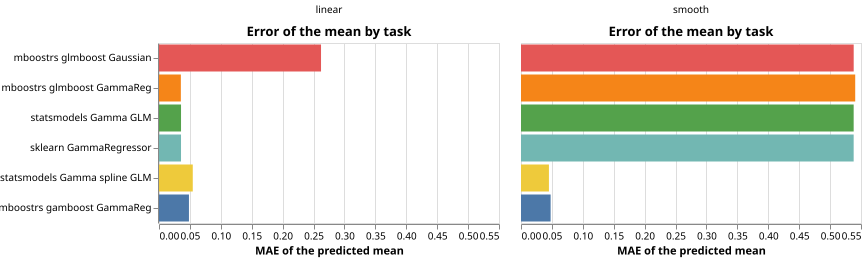

In [6]:
chart_rows = summary.filter(pl.col("method") != "generating Gamma")
alt.Chart(chart_rows).mark_bar().encode(
    x=alt.X("mae:Q", title="MAE of the predicted mean"),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=340,
    height=180,
    title="Error of the mean by task",
).facet(column=alt.Column("task:N", title=None))


## The linear log-mean

`glmboost` with `GammaReg` matches the gamma GLM. Mean test log score at the fit's shape is {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'gamma_nll'):.4f}"` nats per row, against {eval}`f"{value('linear', 'statsmodels Gamma GLM', 'gamma_nll'):.4f}"` for statsmodels and {eval}`f"{value('linear', 'sklearn GammaRegressor', 'gamma_nll'):.4f}"` for `GammaRegressor(alpha=0)`. The generating density scores {eval}`f"{value('linear', 'generating Gamma', 'gamma_nll'):.4f}"`. Mean absolute error of the mean is {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'mae'):.3f}"` for `glmboost` and {eval}`f"{value('linear', 'statsmodels Gamma GLM', 'mae'):.3f}"` for the GLM. The estimated shape is {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'shape'):.2f}"` against the generating value 4. Cross-validation stopped inside the 400-step path on every seed (mean chosen step {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'mstop'):.0f}"`). The GLM takes a few milliseconds; the cross-validated boost takes about {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'seconds'):.2f}"` seconds because it scores every step.

Boosting starts from a constant offset, the log of the mean response, and adds the learners to it; the offset is stored apart from the coefficients. On training seed 0 the coefficients agree with the GLM once the offset is added to the intercept, which `coef(off2int=True)` does. statsmodels reports intercept {eval}`f"{bench['recovery']['statsmodels']['Intercept']:.4f}"`, `x1` {eval}`f"{bench['recovery']['statsmodels']['x1']:.4f}"`, `x2` {eval}`f"{bench['recovery']['statsmodels']['x2']:.4f}"`. `coef(off2int=True)` reports {eval}`f"{bench['recovery']['glmboost_off2int']['(Intercept)']:.4f}"`, {eval}`f"{bench['recovery']['glmboost_off2int']['x1']:.4f}"`, {eval}`f"{bench['recovery']['glmboost_off2int']['x2']:.4f}"`.

`coef()` without `off2int` reports intercept {eval}`f"{bench['recovery']['glmboost_raw_intercept']:.4f}"`, because the offset ({eval}`f"{bench['recovery']['offset']:.4f}"`) is not included. In-sample `logLik()` is {eval}`f"{bench['recovery']['glmboost_loglik']:.2f}"` against the GLM's {eval}`f"{bench['recovery']['statsmodels_llf']:.2f}"`.

A spline in `x1` is unneeded flexibility here: the spline GLM's absolute error rises to {eval}`f"{value('linear', 'statsmodels Gamma spline GLM', 'mae'):.3f}"`. `gamboost` with a P-spline on `x1` and linear terms for the other columns is closer to the linear fits than the spline GLM is (absolute error {eval}`f"{value('linear', 'mboostrs gamboost GammaReg', 'mae'):.3f}"`), and its cross-validated step count stays well below the 1,000-step cap.

`Gaussian` with an identity link does not estimate this mean. Absolute error is {eval}`f"{value('linear', 'mboostrs glmboost Gaussian', 'mae'):.3f}"`, about seven times the gamma fits, and on every seed between {eval}`f"{nonpositive_range('linear', 'mboostrs glmboost Gaussian')[0]}"` and {eval}`f"{nonpositive_range('linear', 'mboostrs glmboost Gaussian')[1]}"` of the 4,000 predictions are negative. The identity link permits negative predictions, whereas the generating mean is positive and exponential in the linear predictor.

## The smooth log-mean

A linear gamma model misses the sine. The linear GLM scores {eval}`f"{value('smooth', 'statsmodels Gamma GLM', 'nll_true'):.3f}"` nats per row at the true shape, and `glmboost` with the same linear formula scores {eval}`f"{value('smooth', 'mboostrs glmboost GammaReg', 'nll_true'):.3f}"`. Absolute error is {eval}`f"{value('smooth', 'statsmodels Gamma GLM', 'mae'):.3f}"` and {eval}`f"{value('smooth', 'mboostrs glmboost GammaReg', 'mae'):.3f}"`. The generating density scores {eval}`f"{value('smooth', 'generating Gamma', 'gamma_nll'):.3f}"`.

`gamboost` with `bbs(x1) + bols(x2) + bols(noise)` (a P-spline in `x1` and linear terms in the other two columns) scores {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'nll_true'):.4f}"` at the true shape. The B-spline gamma GLM scores {eval}`f"{value('smooth', 'statsmodels Gamma spline GLM', 'nll_true'):.4f}"`. Absolute error is {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'mae'):.3f}"` against {eval}`f"{value('smooth', 'statsmodels Gamma spline GLM', 'mae'):.3f}"`. The two smooth fits agree with each other and with the generating shape (about {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'shape'):.2f}"`). Both beat the linear gamma fits by roughly half a nat per row. The boosting path is not at its cap: the mean chosen step is {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'mstop'):.0f}"` of the 1,000 that were fitted, and the run takes about {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'seconds'):.2f}"` seconds against a few milliseconds for the spline GLM. The spline GLM fits the specified smooth directly. Boosting adds one term per step, the one that most reduces the loss, so it updates `x1` repeatedly and leaves `noise` unused.

The log score **at the fit's own shape** differs between the two linear gamma fits although their means are the same. `glmboost` scores {eval}`f"{value('smooth', 'mboostrs glmboost GammaReg', 'gamma_nll'):.3f}"` and the linear GLM scores {eval}`f"{value('smooth', 'statsmodels Gamma GLM', 'gamma_nll'):.3f}"`, with shapes {eval}`f"{value('smooth', 'mboostrs glmboost GammaReg', 'shape'):.2f}"` and {eval}`f"{value('smooth', 'statsmodels Gamma GLM', 'shape'):.2f}"`. At shape 4 the two means score the same, as their absolute errors do. The difference comes from the shape estimators: `GammaReg` reports the maximum-likelihood shape given its fitted mean, and the GLM's `1/scale` is the Pearson estimate. The two agree when the mean is right (the linear task, both near 3.97) and separate when the mean is wrong. Neither linear fit recovers the generating shape 4.

`Gaussian` again matches the linear gamma fits on absolute error ({eval}`f"{value('smooth', 'mboostrs glmboost Gaussian', 'mae'):.3f}"`) and predicts negative means ({eval}`f"{nonpositive_range('smooth', 'mboostrs glmboost Gaussian')[0]}"` to {eval}`f"{nonpositive_range('smooth', 'mboostrs glmboost Gaussian')[1]}"` of 4,000 test rows).

## Prediction and parameter accessors

The examples below use the first linear training sample.

`predict` defaults to `type="link"`. For `GammaReg` that is the log mean, and `type="response"` is the mean: on this sample the two agree with `exp` to {eval}`probe("predict default is the log mean")["detail"].split("to ")[1].split(";")[0]`. A caller who treats `predict()` as `E[Y]` scores the log mean. The benchmark uses `type="response"`.

`nuisance()` on `GammaReg` returns the shape $k$, for which the variance is `mu**2 / k`; a gamma GLM's dispersion (`GLM.scale` in statsmodels) is $1/k$. On a 30-step path this sample reports {eval}`probe("GammaReg nuisance is the shape")["detail"].split(". Variance")[0]`. Comparing that number with `GLM.scale` without taking the reciprocal makes a correct fit look about 15 times too precise or too noisy: the factor is the shape
squared, and the fitted shape is near 3.9.

`coef()` does not include the offset. On seed 0 the raw intercept is {eval}`f"{bench['recovery']['glmboost_raw_intercept']:.3f}"` and the intercept that matches the GLM is {eval}`f"{bench['recovery']['glmboost_off2int']['(Intercept)']:.3f}"`, from `coef(off2int=True)`. The slopes match either way.

`autospec` names `GammaReg` on this positive continuous sample from the data type of the response, without a comparison of held-out scores (its output lists `family` among the choices it made by default). The formula it writes puts a P-spline on every column, including `noise`:

> {eval}`probe("autospec on a gamma sample")["detail"]`

`GammaReg` matches the generating response family. The proposed spline formula is more flexible than the linear generating predictor; the linear-task table measures the resulting prediction error.

A zero response is refused with the family name and the failing value:

> {eval}`probe("GammaReg rejects a zero")["detail"]`

A P-spline's basis is defined between its boundary knots, the smallest and largest training values. Predicting a `bbs` fit outside that range warns, and the warning names the options:

> {eval}`probe("bbs predict outside the training range")["detail"]`

The benchmark passes `extrapolation="allow"` on the test predictions so the edge slope is an explicit choice; on the first linear sample one test value of `x1` lies above the training range.

Passing `GammaLSS()` to a single-predictor `gamboost` call is rejected
with a message directing the caller to the distributional entry points:

> {eval}`probe("gamboost(family=GammaLSS())")["detail"]`

`cvrisk` runs on a model extended with `continue_to(...)`, for both `gamboost` and `glmboost` fits. The Gaussian baseline has no nuisance parameter; its `nuisance()` result is:

> {eval}`probe("glmboost Gaussian nuisance()")["detail"]`

## Reproduction

From the repository root, with `statsmodels`, `patsy` and `scikit-learn` installed:

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
    python benches/bench_gamma.py --out docs/book/cases/bench_gamma.json
```

The tables read that file, which also records the library versions. Elapsed times are means over the four training seeds; each method's time covers its own fit, tuning and prediction.